# code_072 · Linear regression and robust alternatives

**Book:** section 15.1. A self-contained transparent response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_15_GUIDE.md), [run evidence](../CHAPTER_15_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_072).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1572;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1572


<a id="losses"></a>
## Match the response target to the loss

Generate strain in microstrain at loads 10–70 kN: strain=100+2*load+Normal(0,5+.1*load). Training240, development100 and final400 are independent. Exactly twelve training responses receive an additional180 microstrain measurement error; development/final remain clean. Fixed OLS, Huber(epsilon1.35,alpha0) and unpenalized quantile fits(.1,.5,.9) all use the same load feature. No final-driven selection; development is an unused reserved role. Evaluate all fits with MSE, MAE and their declared quantile losses. Heteroskedasticity means a straight quantile model is only a family approximation. No confidence intervals or Gaussian-error inference are asserted.


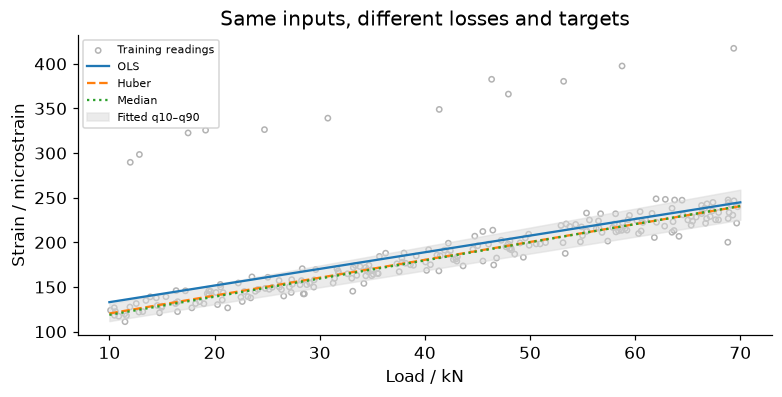

In [2]:
from sklearn.linear_model import LinearRegression,HuberRegressor,QuantileRegressor
from sklearn.metrics import mean_squared_error,mean_absolute_error,mean_pinball_loss
def generate(n):
 x=rng.uniform(10,70,n);return x[:,None],100+2*x+rng.normal(0,5+.1*x,n)
X,y=generate(240);Xd,yd=generate(100);Xt,yt=generate(400);bad=rng.choice(len(y),12,replace=False);y[bad]+=180
models={'OLS':LinearRegression(),'Huber':HuberRegressor(epsilon=1.35,alpha=0,max_iter=1000),'Median':QuantileRegressor(quantile=.5,alpha=0),'q10':QuantileRegressor(quantile=.1,alpha=0),'q90':QuantileRegressor(quantile=.9,alpha=0)};rows=[]
for name,model in models.items():
 model.fit(X,y);p=model.predict(Xt);rows.append({'model':name,'slope_microstrain_per_kN':float(model.coef_[0]),'intercept_microstrain':float(model.intercept_),'final_mse':float(mean_squared_error(yt,p)),'final_mae':float(mean_absolute_error(yt,p)),'final_fraction_below_prediction':float(np.mean(yt<=p)),'final_pinball_at_reporting_quantile':float(mean_pinball_loss(yt,p,alpha=.5 if name not in ['q10','q90'] else .1 if name=='q10' else .9))})
Z=np.column_stack([np.ones(len(X)),X[:,0]]);resid=y-models['OLS'].predict(X);np.testing.assert_allclose(Z.T@resid,0,atol=1e-7)
qlo=models['q10'].predict(Xt);qhi=models['q90'].predict(Xt);assert np.all(qlo<=qhi)
RESULTS['fits']=rows;RESULTS['protocol']={'train':240,'unused_development':100,'clean_final':400,'contaminated_training_rows':12,'final_q10_q90_coverage':float(np.mean((yt>=qlo)&(yt<=qhi))),'quantile_crossings_in_final':int(np.sum(qlo>qhi))}
grid=np.linspace(10,70,150)[:,None];fig,ax=plt.subplots(figsize=(7,3.5));ax.scatter(X[:,0],y,s=12,facecolors='none',edgecolors='.7',label='Training readings')
for name,style in [('OLS','-'),('Huber','--'),('Median',':')]:ax.plot(grid[:,0],models[name].predict(grid),style,label=name)
ax.fill_between(grid[:,0],models['q10'].predict(grid),models['q90'].predict(grid),color='.85',alpha=.5,label='Fitted q10–q90');ax.set(xlabel='Load / kN',ylabel='Strain / microstrain',title='Same inputs, different losses and targets');ax.legend(fontsize=7);plt.show()


<a id="geometry"></a>
## Coefficients can be nonunique while predictions agree

Duplicate load into two identical columns. A least-squares solution is not unique: adding t to one slope and subtracting t from the other preserves every fitted prediction. This algebraic audit is separate from stochastic assumptions. Zero residual correlation with the fitted design follows least-squares optimization; it does not prove the model form, independent errors, homoskedasticity or exogeneity. The final residual panel uses unchanged clean final observations for all procedures.


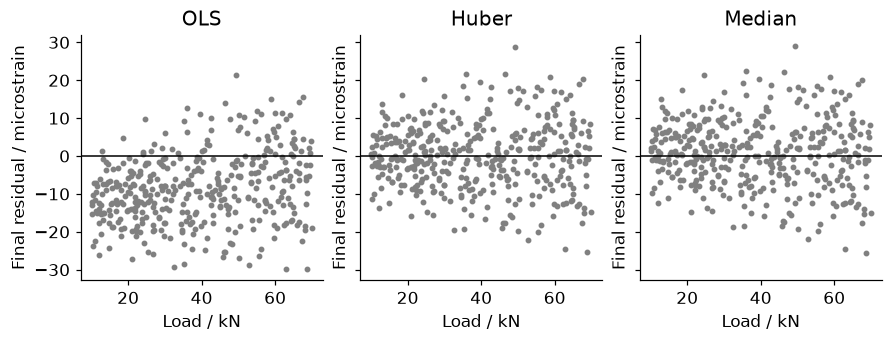

In [3]:
D=np.column_stack([np.ones(len(X)),X[:,0],X[:,0]]);b=np.linalg.lstsq(D,y,rcond=None)[0];assert np.linalg.matrix_rank(D)==2;np.testing.assert_allclose(D@b,D@(b+np.array([0,7,-7])),atol=1e-10)
RESULTS['geometry']={'duplicate_design_columns':3,'rank':int(np.linalg.matrix_rank(D)),'null_direction':[0,7,-7],'training_normal_equations_checked':True,'inference_assumptions_established':False}
fig,axes=plt.subplots(1,3,figsize=(8,3),sharex=True,sharey=True)
for ax,name in zip(axes,['OLS','Huber','Median']):ax.scatter(Xt[:,0],yt-models[name].predict(Xt),s=8,color='.5');ax.axhline(0,color='black',lw=1);ax.set(title=name,xlabel='Load / kN',ylabel='Final residual / microstrain')
plt.show()


In [4]:
summary={'example_id':'code_072','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['least squares geometry and rank deficiency', 'contaminated training responses', 'median and conditional quantile targets', 'fitting versus inference assumptions'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["least squares geometry and rank deficiency", "contaminated training responses", "median and conditional quantile targets", "fitting versus inference assumptions"], "elapsed_seconds": 0.274, "example_id": "code_072", "hardware": "Darwin arm64 CPU", "results": {"fits": [{"final_fraction_below_prediction": 0.8325, "final_mae": 10.56828289252839, "final_mse": 158.50005855697137, "final_pinball_at_reporting_quantile": 5.284141446264195, "intercept_microstrain": 114.31805481208684, "model": "OLS", "slope_microstrain_per_kN": 1.8636314295835532}, {"final_fraction_below_prediction": 0.5025, "final_mae": 7.012372051343032, "final_mse": 79.15053058065752, "final_pinball_at_reporting_quantile": 3.506186025671516, "intercept_microstrain": 100.31304915629819, "model": "Huber", "slope_microstrain_per_kN": 2.0015190321003997}, {"final_fraction_below_prediction": 0.46, "final_mae": 7.041545840264938, "final_mse": 80.1145378360066, "final_pinball_at_re